# Baseline: predicción de siniestros fatales por departamento y mes

Se entrenan y comparan dos modelos simples (regresión lineal y árbol de regresión) para
predecir `siniestros` a partir de los rezagos y la fecha. Funciones en `src/models.py` y
`src/evaluation.py`.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt

from src.models import entrenar_regresion_lineal, entrenar_arbol_regresion
from src.evaluation import evaluar_modelo

%matplotlib inline

## Cargar datos

In [2]:
dataset = pd.read_csv('../data/processed/dataset_modelo.csv')
dataset.head()

,departamento,periodo,siniestros,lag_1,lag_2,lag_3,prom_movil_3,anio,mes
0,AMAZONAS,2021-04,1,2.0,2.0,4.0,2.666667,2021,4
1,AMAZONAS,2021-05,2,1.0,2.0,2.0,1.666667,2021,5
2,AMAZONAS,2021-06,0,2.0,1.0,2.0,1.666667,2021,6
3,AMAZONAS,2021-07,0,0.0,2.0,1.0,1.000000,2021,7
4,AMAZONAS,2021-08,2,0.0,0.0,2.0,0.666667,2021,8


## Preparar variables

`departamento` se convierte en variables dummy. Las variables numéricas son los rezagos, el
promedio móvil, el año y el mes.

In [3]:
X = pd.get_dummies(dataset.drop(columns=['siniestros', 'periodo']), columns=['departamento'], drop_first=True)
y = dataset['siniestros']

print('X:', X.shape)
X.head()

X: (1125, 30)


,lag_1,lag_2,lag_3,prom_movil_3,anio,mes,departamento_ANCASH,departamento_APURIMAC,departamento_AREQUIPA,departamento_AYACUCHO,...,departamento_LORETO,departamento_MADRE DE DIOS,departamento_MOQUEGUA,departamento_PASCO,departamento_PIURA,departamento_PUNO,departamento_SAN MARTIN,departamento_TACNA,departamento_TUMBES,departamento_UCAYALI
0,2.0,2.0,4.0,2.666667,2021,4,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1.0,2.0,2.0,1.666667,2021,5,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,2.0,1.0,2.0,1.666667,2021,6,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,0.0,2.0,1.0,1.000000,2021,7,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0.0,0.0,2.0,0.666667,2021,8,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## Dividir en train y test

Como los datos tienen orden temporal, el conjunto de prueba son los últimos meses
(abril-diciembre 2024) y el de entrenamiento son los meses anteriores. Así se evita usar
información del futuro para predecir el pasado.

In [4]:
es_test = dataset['periodo'] >= '2024-04'

X_train, X_test = X[~es_test], X[es_test]
y_train, y_test = y[~es_test], y[es_test]

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (900, 30)
Prueba: (225, 30)


## Entrenar modelos

In [5]:
modelo_lineal = entrenar_regresion_lineal(X_train, y_train)
modelo_arbol = entrenar_arbol_regresion(X_train, y_train, max_depth=5)

pred_lineal = modelo_lineal.predict(X_test)
pred_arbol = modelo_arbol.predict(X_test)

## Evaluar modelos

In [6]:
resultados = [
    evaluar_modelo('Regresion lineal', y_test, pred_lineal),
    evaluar_modelo('Arbol de regresion', y_test, pred_arbol),
]

metrics = pd.DataFrame(resultados)
metrics

,modelo,MAE,RMSE
0,Regresion lineal,2.239655,3.245885
1,Arbol de regresion,1.890078,3.385944


In [7]:
metrics.to_csv('../results/metrics.csv', index=False)
metrics

,modelo,MAE,RMSE
0,Regresion lineal,2.239655,3.245885
1,Arbol de regresion,1.890078,3.385944


## Comparación gráfica

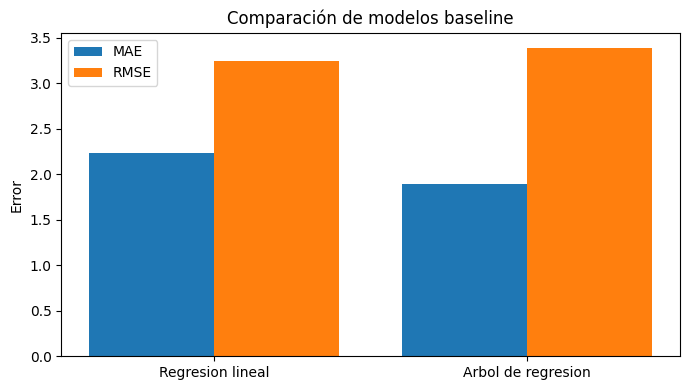

In [8]:
x = range(len(metrics))

plt.figure(figsize=(7, 4))
plt.bar([i - 0.2 for i in x], metrics['MAE'], width=0.4, label='MAE')
plt.bar([i + 0.2 for i in x], metrics['RMSE'], width=0.4, label='RMSE')
plt.xticks(list(x), metrics['modelo'])
plt.ylabel('Error')
plt.title('Comparación de modelos baseline')
plt.legend()
plt.tight_layout()
plt.savefig('../results/plots/comparacion_modelos.png')
plt.show()

## Guardar resumen de resultados

In [9]:
mejor = metrics.sort_values('RMSE').iloc[0]

resumen = f"""Comparacion de modelos baseline - Entregable Parcial
Variable objetivo: siniestros fatales por departamento y mes
Entrenamiento: 2021-04 a 2024-03 ({X_train.shape[0]} filas)
Prueba: 2024-04 a 2024-12 ({X_test.shape[0]} filas)

{metrics.to_string(index=False)}

Mejor modelo: {mejor['modelo']} (MAE={mejor['MAE']:.3f}, RMSE={mejor['RMSE']:.3f})

El MAPE no se usa porque el 21% de las filas tiene siniestros = 0 (division por cero).
Estos resultados son un baseline inicial para el Entregable Parcial. En el Entregable Final
se compararan ademas KNN y MLP, segun lo propuesto en el README.
"""

with open('../results/model_comparison.txt', 'w', encoding='utf-8') as f:
    f.write(resumen)

print(resumen)

Comparacion de modelos baseline - Entregable Parcial
Variable objetivo: siniestros fatales por departamento y mes
Entrenamiento: 2021-04 a 2024-03 (900 filas)
Prueba: 2024-04 a 2024-12 (225 filas)

            modelo      MAE     RMSE
  Regresion lineal 2.239655 3.245885
Arbol de regresion 1.890078 3.385944

Mejor modelo: Regresion lineal (MAE=2.240, RMSE=3.246)

El MAPE no se usa porque el 21% de las filas tiene siniestros = 0 (division por cero).
Estos resultados son un baseline inicial para el Entregable Parcial. En el Entregable Final
se compararan ademas KNN y MLP, segun lo propuesto en el README.

